# Analyser dine eigne målingar

Denne notatboka les CSV-fila du har logga med Arduinoen, ryddar ho og lagar grafar. Ho fungerer for begge loggemåtane:

- **Spor A (seriell → Python):** fila har kolonnane `tid,temperatur`
- **Spor B (SD-kort):** fila har kolonnane `sekund,temperatur`

Før du har eigne data, kan du bruke eksempelfilene i `eksempeldata/`. **Merk:** Desse er *simulerte* (laga med ein matematisk modell pluss litt tilfeldig støy), ikkje ekte målingar.

- `maalingar-eksempel.csv`: ein kopp varmt vatn som kjølner (spor A)
- `LOGG00.CSV`: temperaturen i eit klasserom der vindauget vart opna ei stund (spor B)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)

---
## Spor A: Fil med tidspunkt

Byt ut filnamnet med di eiga fil, t.d. `"maalingar.csv"`.

In [2]:
FILNAMN = "eksempeldata/maalingar-eksempel.csv"

data = pd.read_csv(FILNAMN, parse_dates=["tid"], index_col="tid")
print("Tal på målingar:", len(data))
data.head()

Tal på målingar: 720


,temperatur
tid,
2026-11-10 09:15:03,21.31
2026-11-10 09:15:08,21.31
2026-11-10 09:15:13,21.31
2026-11-10 09:15:18,21.25
2026-11-10 09:15:23,21.25


### Rydd: fjern feilverdiar frå DS18B20

DS18B20 har to kjende feilverdiar:

| Verdi | Tyding |
|---|---|
| **−127** | Arduinoen fekk ikkje kontakt med sensoren (laus leidning, manglande motstand) |
| **85** | Sensoren har nettopp starta og har ikkje målt enno (ofte dårleg straumtilførsel) |

Vi gjer dei om til `NaN`. Ein ekte måling på nøyaktig 85,00 °C er svært lite sannsynleg i forsøka våre.

In [3]:
def rydd_ds18b20(data):
    feil = (data["temperatur"] == -127) | (data["temperatur"] == 85)
    print("Feilverdiar funne:", feil.sum())
    data.loc[feil, "temperatur"] = np.nan
    return data

data = rydd_ds18b20(data)
data.describe().round(2)

Feilverdiar funne: 1


,temperatur
count,719.00
mean,38.20
std,14.68
min,21.25
25%,26.31
50%,32.69
75%,46.72
max,78.00


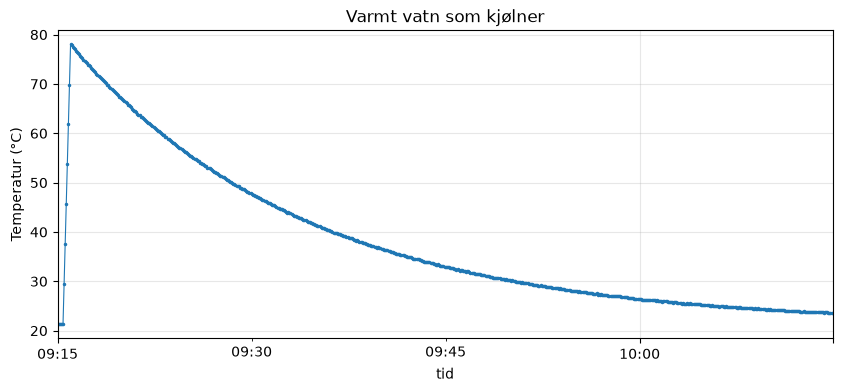

In [4]:
ax = data["temperatur"].plot(marker=".", markersize=3, linewidth=0.8)
ax.set_title("Varmt vatn som kjølner")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.3)
plt.show()

### Kor fort kjølner vatnet?

Vi kan rekne ut **endringa per minutt**. Då samanliknar vi kvar måling med målinga eitt minutt før.

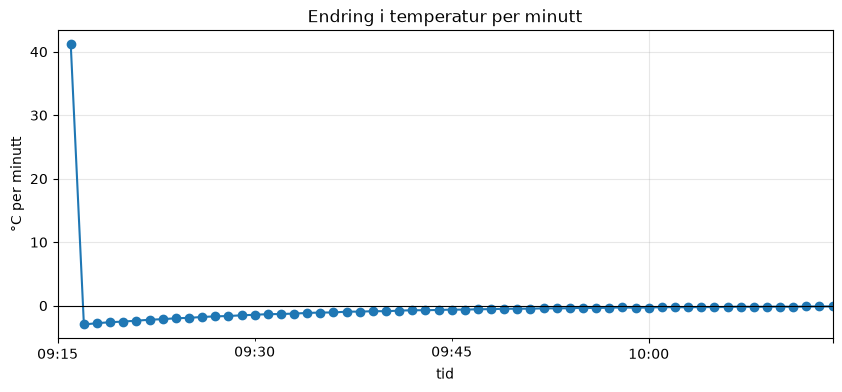

In [5]:
per_minutt = data["temperatur"].resample("1min").mean()
endring = per_minutt.diff()     # endring frå eitt minutt til det neste

ax = endring.plot(marker="o")
ax.set_title("Endring i temperatur per minutt")
ax.set_ylabel("°C per minutt")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(alpha=0.3)
plt.show()

Vatnet kjølner raskast i starten, når skilnaden mellom vatnet og rommet er størst. Dette kallar vi **Newtons avkjølingslov**: farten på avkjølinga er proporsjonal med temperaturskilnaden til omgivnadene.

### Kor lang tid tok det å kome under 40 °C?

In [6]:
over_40 = data[data["temperatur"] >= 40]
start = over_40.index.min()
slutt = over_40.index.max()
print("Over 40 °C frå", start.time(), "til", slutt.time())
print("Tid over 40 °C:", slutt - start)

Over 40 °C frå 09:15:43 til 09:36:18
Tid over 40 °C: 0 days 00:20:35


---
## Spor B: Fil frå SD-kort (sekund sidan start)

Fila frå SD-kortet har ikkje klokkeslett, berre kor mange sekund som har gått sidan Arduinoen starta. Skreiv du ned når du starta loggaren, kan vi rekne ut det ekte tidspunktet.

In [7]:
FILNAMN_SD = "eksempeldata/LOGG00.CSV"
STARTTID = "2026-11-10 08:00:00"     # når du skrudde på loggaren

sd = pd.read_csv(FILNAMN_SD)
sd.head()

,sekund,temperatur
0,0,85.00
1,10,21.81
2,20,21.75
3,30,21.81
4,40,21.75


In [8]:
sd["tid"] = pd.Timestamp(STARTTID) + pd.to_timedelta(sd["sekund"], unit="s")
sd = sd.set_index("tid")
sd = rydd_ds18b20(sd)
sd.head()

Feilverdiar funne: 1


,sekund,temperatur
tid,,
2026-11-10 08:00:00,0,NaN
2026-11-10 08:00:10,10,21.81
2026-11-10 08:00:20,20,21.75
2026-11-10 08:00:30,30,21.81
2026-11-10 08:00:40,40,21.75


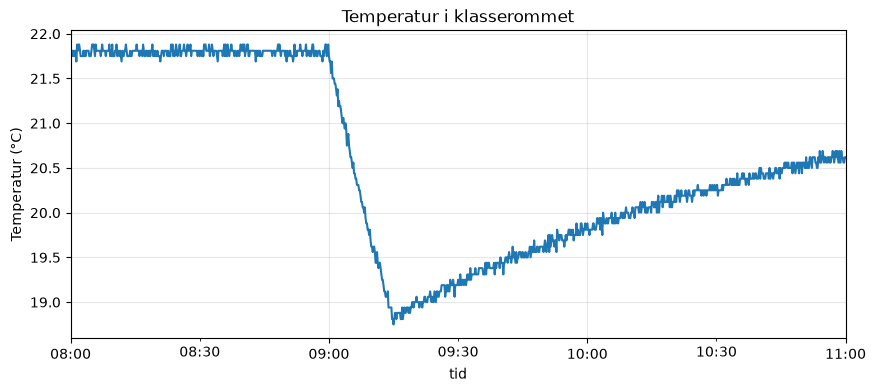

In [9]:
ax = sd["temperatur"].plot()
ax.set_title("Temperatur i klasserommet")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.3)
plt.show()

Kva skjedde rundt klokka 09:00? Er temperaturen tilbake på normalen når loggen sluttar? Kvifor går det så mykje seinare å varme opp rommet enn å kjøle det ned?

---
## Kor sikre er målingane?

Når du presenterer resultata dine, må du seie noko om **usikkerheita**. Nokre ting å vurdere:

1. **Nøyaktigheit:** DS18B20 er oppgitt til ±0,5 °C. Viss to grupper måler same vatn og får 21,3 °C og 21,7 °C, kan begge ha rett.
2. **Oppløysing:** Sensoren gir verdiar i steg på 0,0625 °C. Derfor ser grafen «trappeforma» ut når temperaturen endrar seg sakte.
3. **Støy:** Sjå på ein periode der temperaturen burde vore stabil. Kor mykje varierer målingane? Standardavviket gir eit mål på dette:

In [10]:
stabil = data.loc[:data.index.min() + pd.Timedelta(seconds=25), "temperatur"]
print("Målingar før vatnet vart helt i:", list(stabil))
print("Standardavvik:", round(stabil.std(), 3), "°C")

Målingar før vatnet vart helt i: [21.31, 21.31, 21.31, 21.25, 21.25, 21.25]
Standardavvik: 0.033 °C


4. **Responstid:** Sensoren brukar litt tid på å varme seg opp. Sjå på dei første minutta i avkjølingsforsøket: Temperaturen stig ikkje momentant til 78 °C.
5. **Systematiske feil:** Viser sensoren 0 °C i isvatn? Har du kalibrert han?

### Korleis kan usikkerheita reduserast?

- Ta **fleire målingar** og rekn gjennomsnitt (reduserer tilfeldig støy, men ikkje systematiske feil).
- **Kalibrer** sensoren mot ein kjend temperatur (isvatn = 0 °C) og korriger for avviket.
- Bruk **fleire sensorar** og samanlikn.
- Kontroller **forholda**: same plassering, same mengd vatn, lokk eller ikkje lokk.

---
## Lagre ein figur

Vil du bruke figuren i ein rapport eller presentasjon? Lagre han som bilete:

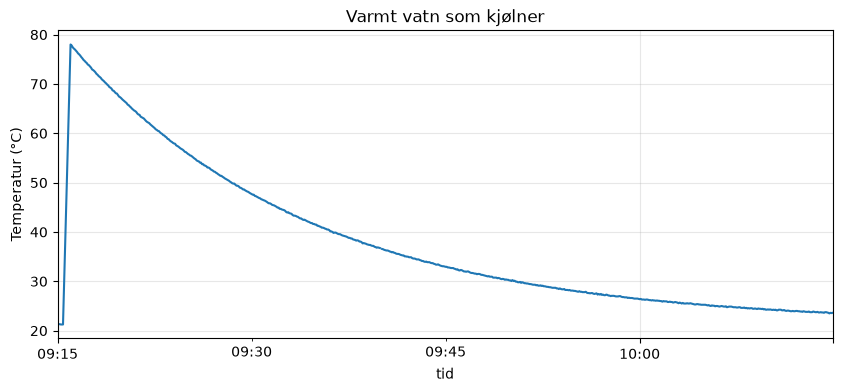

In [11]:
ax = data["temperatur"].plot()
ax.set_title("Varmt vatn som kjølner")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.3)
plt.savefig("min-figur.png", dpi=150, bbox_inches="tight")
plt.show()